# Hackathon 5: Who will not pay their credit card bill next month?

**Data:** UCI "Default of Credit Card Clients" (CC BY 4.0), 30,000 clients of a bank in Taiwan, April to September 2005. https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients

**How the CSV was made:** the UCI download is an Excel file (`default of credit card clients.xls`). We read it with pandas (`pd.read_excel(..., header=1)`, because the first row is a title) and saved it as `credit_card_default.csv`. The CSV is in our GitHub repo and this notebook loads it from there, so "Run all" works without uploading anything.

## Step 1. Frame the problem
- **User:** the collections team of a bank. They can only call part of the clients each month.
- **Question:** which clients will miss their next payment, so the team can call them early and offer a repayment plan?
- **Target:** `default payment next month`. The positive class (1) is a client who **misses** the payment.
- **Which mistake is worse?** Missing a defaulter (nobody calls, the debt grows) is worse for the client and the bank than calling someone who would have paid (a wasted call). But if we call everybody, the team has no time left. So we need both: find many defaulters (recall) without too many wasted calls (precision).
- **Why F1?** F1 combines precision and recall in one number. Only 22% of clients default, so accuracy is misleading: a model that always says "no default" already gets 78%.

## Step 2. Load the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

url = "https://raw.githubusercontent.com/landinh0804/ai4g-portfolio-Dylan/main/Term%201/Week%205/hackathon/credit_card_default.csv"
df = pd.read_csv(url).drop(columns="ID")
print("Rows and columns:", df.shape)

pandas 2.2.3 | scikit-learn 1.6.1
Rows and columns: (30000, 24)


## Step 3. Explore and clean the data
We check missing values, duplicates, the class balance, and codes that the dataset description does not explain.

In [2]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print(df["default payment next month"].value_counts(normalize=True).round(3))
print()
print(df["EDUCATION"].value_counts().sort_index())
print(df["MARRIAGE"].value_counts().sort_index())

Missing values: 0
Duplicate rows: 35
default payment next month
0    0.779
1    0.221
Name: proportion, dtype: float64

EDUCATION
0       14
1    10563
2    14019
3     4915
4      123
5      280
6       51
Name: count, dtype: int64
MARRIAGE
0       54
1    13643
2    15945
3      323
Name: count, dtype: int64


Next we look at the size and spread of every column (minimum and maximum) and at the repayment status columns, to find impossible or unexplained values.

In [3]:
print(df.describe().T[["min", "max"]].round(0))
print()
print("PAY_0 values:", sorted(df["PAY_0"].unique()))

                                 min        max
LIMIT_BAL                    10000.0  1000000.0
SEX                              1.0        2.0
EDUCATION                        0.0        6.0
MARRIAGE                         0.0        3.0
AGE                             21.0       79.0
PAY_0                           -2.0        8.0
PAY_2                           -2.0        8.0
PAY_3                           -2.0        8.0
PAY_4                           -2.0        8.0
PAY_5                           -2.0        8.0
PAY_6                           -2.0        8.0
BILL_AMT1                  -165580.0   964511.0
BILL_AMT2                   -69777.0   983931.0
BILL_AMT3                  -157264.0  1664089.0
BILL_AMT4                  -170000.0   891586.0
BILL_AMT5                   -81334.0   927171.0
BILL_AMT6                  -339603.0   961664.0
PAY_AMT1                         0.0   873552.0
PAY_AMT2                         0.0  1684259.0
PAY_AMT3                         0.0   8

- **Dropped:** the `ID` column (just a row number, no information) and the 35 duplicate rows. Nothing else is dropped.
- **Impossible values:** none. AGE and LIMIT_BAL are in a sensible range. Some bill amounts are negative, which means the client has a credit on the card, so we keep them.
- **Unexplained values:** the repayment status columns (`PAY_0` to `PAY_6`) also contain -2 and 0, which the description does not explain (it only explains -1 = paid on time and 1 to 9 = months late). They are very common, so we keep them as numbers. A value of 1 or more always means "late".
- **Order:** the brief says to split before cleaning. We remove duplicates before the split on purpose, so the same client row cannot end up in both train and test. The recoding below is a fixed rule, not learned from the data, so it cannot leak information from the test set.

- No missing values. We remove the 35 duplicate rows. 22% of clients default.
- The description only explains EDUCATION 1 to 4 and MARRIAGE 1 to 3. The codes EDUCATION 0, 5, 6 and MARRIAGE 0 are not documented, but there are few of them. We put them in the existing "other" group (EDUCATION 4, MARRIAGE 3) instead of deleting clients.
- **Does any column leak the answer?** No. The target is about the **next** month. All columns (limit, bills, payments and repayment status) describe earlier months, so the bank would know them before calling.

In [4]:
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})

## Step 4. Split the data first
We put 20% of the clients aside as a test set and use it only once, at the end. `stratify=y` keeps the same share of defaulters in both parts and `random_state=42` makes the result repeatable.

In [5]:
y = df.pop("default payment next month")
X = df
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(len(X_train), "training clients,", len(X_test), "test clients")

23972 training clients, 5993 test clients


## Step 5. Baseline
The baseline always predicts "no default". Every real model has to beat it.

In [6]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

DummyClassifier(strategy='most_frequent')

## Step 6. Three models, tuned with cross-validation
SEX, EDUCATION and MARRIAGE are categories, not quantities, so we one-hot encode them. All other columns are scaled. This preparation (`prep`) is the first step of every Pipeline, so it is only learned from the training data.

- **KNN:** copies the answer of the most similar clients.
- **Logistic regression:** draws a straight line between the two groups.
- **Random forest (our own choice):** many small decision trees that vote.

`GridSearchCV` tries a few settings with 5-fold cross-validation on the **training set only** and keeps the best one. We choose by F1.

In [7]:
categories = ["SEX", "EDUCATION", "MARRIAGE"]
numbers = [c for c in X.columns if c not in categories]
prep = ColumnTransformer([("categories", OneHotEncoder(handle_unknown="ignore"), categories),
                          ("numbers", StandardScaler(), numbers)])

In [8]:
knn = GridSearchCV(
    Pipeline([("prep", prep), ("model", KNeighborsClassifier())]),
    {"model__n_neighbors": [5, 15, 31, 51]},
    cv=5, scoring="f1")
knn.fit(X_train, y_train)
print("KNN:", knn.best_params_)

KNN: {'model__n_neighbors': 15}


In [9]:
logreg = GridSearchCV(
    Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
    {"model__C": [0.0001, 0.001, 0.01, 0.1, 1]},
    cv=5, scoring="f1")
logreg.fit(X_train, y_train)
print("Logistic regression:", logreg.best_params_)

Logistic regression: {'model__C': 0.01}


In [10]:
forest = GridSearchCV(
    Pipeline([("prep", prep), ("model", RandomForestClassifier(class_weight="balanced", random_state=42))]),
    {"model__max_depth": [4, 8], "model__min_samples_leaf": [20, 50]},
    cv=5, scoring="f1", n_jobs=2)
forest.fit(X_train, y_train)
print("Random forest:", forest.best_params_)

Random forest: {'model__max_depth': 8, 'model__min_samples_leaf': 50}


**How does the score change with the setting?** For KNN we plot the cross-validated F1 against `n_neighbors`.

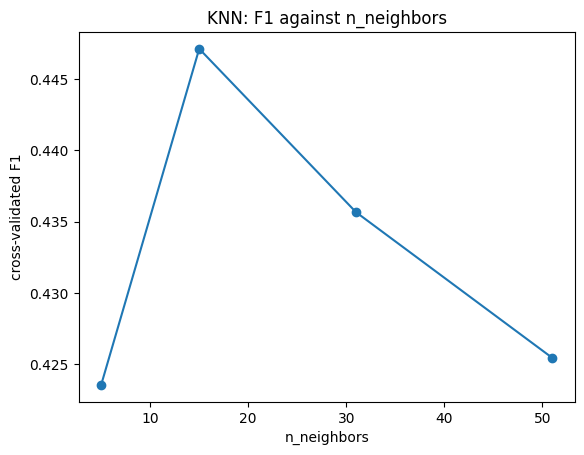

Logistic regression, F1 for each C:
0.0001    0.458
0.0010    0.473
0.0100    0.481
0.1000    0.480
1.0000    0.479
dtype: float64


In [11]:
plt.plot([5, 15, 31, 51], knn.cv_results_["mean_test_score"], marker="o")
plt.xlabel("n_neighbors")
plt.ylabel("cross-validated F1")
plt.title("KNN: F1 against n_neighbors")
plt.show()

print("Logistic regression, F1 for each C:")
print(pd.Series(logreg.cv_results_["mean_test_score"], index=[0.0001, 0.001, 0.01, 0.1, 1]).round(3))

For logistic regression we added C=0.0001 and C=0.001 to check that the best value is not just the edge of the grid. If the best C is inside the grid, the grid was wide enough.

## Step 7. Compare the models on the test set
This is the one time we use the test set. The table shows the best settings, the cross-validation score (mean ± standard deviation over the 5 folds) and the test scores. The baseline is the first row.

In [12]:
models = {"Baseline (always no default)": baseline, "KNN": knn,
          "Logistic regression": logreg, "Random forest": forest}

rows = []
for name, model in models.items():
    pred = model.predict(X_test)
    if name.startswith("Baseline"):
        settings, cv_text = "-", "-"
    else:
        i = model.best_index_
        settings = str(model.best_params_).replace("model__", "")
        cv_text = f"{model.cv_results_['mean_test_score'][i]:.3f} ± {model.cv_results_['std_test_score'][i]:.3f}"
    rows.append([name, settings, cv_text, precision_score(y_test, pred, zero_division=0),
                 recall_score(y_test, pred), f1_score(y_test, pred)])

table = pd.DataFrame(rows, columns=["model", "best settings", "CV F1 (mean ± std)",
                                    "test precision", "test recall", "test F1"]).set_index("model")
table.round(3)

,best settings,CV F1 (mean ± std),test precision,test recall,test F1
model,,,,,
Baseline (always no default),-,-,0.000,0.000,0.000
KNN,{'n_neighbors': 15},0.447 ± 0.020,0.629,0.340,0.442
Logistic regression,{'C': 0.01},0.481 ± 0.005,0.377,0.633,0.473
Random forest,"{'max_depth': 8, 'min_samples_leaf': 50}",0.543 ± 0.007,0.466,0.611,0.529


**Confusion matrices.** Each box counts clients. Bottom-left are defaulters the model missed, top-right are clients flagged who would have paid.

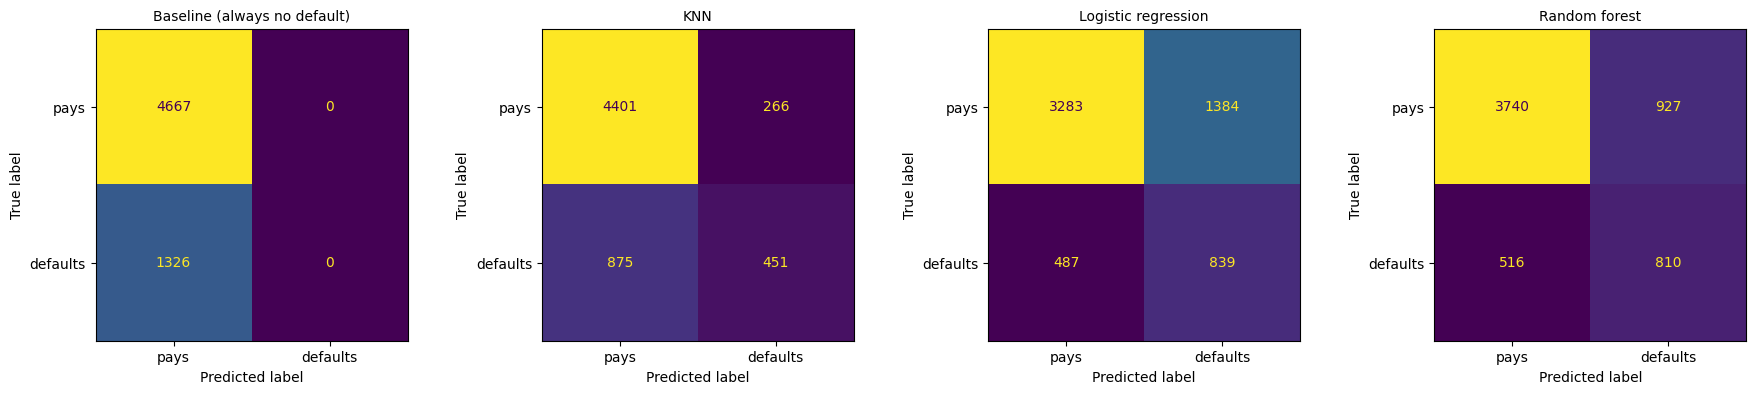

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax, colorbar=False,
                                          display_labels=["pays", "defaults"])
    ax.set_title(name, fontsize=10)
plt.tight_layout()
plt.show()

**Reading the table.** The baseline never finds a defaulter (recall 0). KNN is careful (precision 0.63) but finds only a third of the defaulters. Logistic regression finds the most defaulters (recall 0.63) but also flags many clients who would have paid (precision 0.38). The random forest has the best balance (highest F1, 0.53). The cross-validation standard deviations are small (0.005 to 0.020), so the ranking is stable and not just luck.

**Overfitting or underfitting?** If the training score is much higher than the cross-validation and test scores, the model memorised the training data (overfitting). If all three are low, the model is too simple (underfitting).

In [14]:
fit_rows = []
for name, model in models.items():
    if name.startswith("Baseline"):
        continue
    fit_rows.append([name, f1_score(y_train, model.predict(X_train)), model.best_score_,
                     f1_score(y_test, model.predict(X_test))])
pd.DataFrame(fit_rows, columns=["model", "train F1", "CV F1", "test F1"]).set_index("model").round(3)

,train F1,CV F1,test F1
model,,,
KNN,0.485,0.447,0.442
Logistic regression,0.483,0.481,0.473
Random forest,0.561,0.543,0.529


The three scores are close for every model (the biggest gap is 0.03, for the random forest), so there is no strong overfitting. The scores are also only around 0.45 to 0.55, so the limit is the information in the data, not memorising. Even a flexible model cannot predict next month's behaviour much better than this from these columns.

**Is a simple rule just as good?** A bank does not need a model if a simple rule works. The rule "call everyone who was late last month" means `PAY_0 >= 1`.

In [15]:
rule = (X_test["PAY_0"] >= 1).astype(int)
print("Rule PAY_0 >= 1")
print("  clients called:", round(rule.mean(), 3))
print("  precision:", round(precision_score(y_test, rule), 3))
print("  recall:   ", round(recall_score(y_test, rule), 3))
print("  F1:       ", round(f1_score(y_test, rule), 3))

Rule PAY_0 >= 1
  clients called: 0.223
  precision: 0.498
  recall:    0.503
  F1:        0.501


**Fair test at the same number of calls.** The rule calls a fixed group of clients. The model gives every client a probability, so we can let it call the same number of clients, starting with the highest probability. Who finds more real defaulters?

In [16]:
calls = int(rule.sum())
chance_all = pd.Series(forest.predict_proba(X_test)[:, 1], index=X_test.index)
top_clients = chance_all.nlargest(calls).index

found_model = int(y_test[top_clients].sum())
found_rule = int(y_test[rule.values == 1].sum())
print("Clients called by each:", calls)
print("Real defaulters found by the random forest (top probabilities):", found_model)
print("Real defaulters found by the rule PAY_0 >= 1:", found_rule)
print("Precision of the forest:", round(found_model / calls, 3), "| precision of the rule:", round(found_rule / calls, 3))

Clients called by each: 1339
Real defaulters found by the random forest (top probabilities): 709
Real defaulters found by the rule PAY_0 >= 1: 667
Precision of the forest: 0.529 | precision of the rule: 0.498


At the same number of calls (1,339) the random forest finds 709 real defaulters and the rule finds 667. That is 42 more (about 6%), and a higher precision (0.53 against 0.50). So machine learning does beat the single threshold, but only by a small margin. The real advantage of the model is that it gives a probability: the team can choose how many clients to call and always start with the riskiest ones. The rule can only say yes or no.

**The simple rule is almost as good as our best model.** It has F1 0.50 against 0.53 for the random forest, and it even beats KNN (0.44) and logistic regression (0.47). The two do not call the same number of clients: the rule calls 22% of the clients and the random forest flags about 29% (1,737 clients, of which 810 are real defaulters). That is why we also compare them at the same number of calls, below.

## Step 8. Error analysis: who does the model get wrong?

First: which real defaulters does the random forest **miss**, and what do they look like? We compare the missed ones with the ones it found, using the payment status of last month (`PAY_0`: 0 or less = paid on time or used revolving credit, 1 or more = months late).

In [17]:
pred = forest.predict(X_test)

missed = X_test[(y_test == 1) & (pred == 0)]
found = X_test[(y_test == 1) & (pred == 1)]
print("Real defaulters missed:", len(missed), "| found:", len(found))
print("Missed ones who were on time last month (PAY_0 <= 0):", round((missed["PAY_0"] <= 0).mean(), 2))
print("Found ones who were on time last month (PAY_0 <= 0): ", round((found["PAY_0"] <= 0).mean(), 2))
print()
print("Average credit limit, missed vs found:", round(missed["LIMIT_BAL"].mean()), "vs", round(found["LIMIT_BAL"].mean()))
print("Average payment last month, missed vs found:", round(missed["PAY_AMT1"].mean()), "vs", round(found["PAY_AMT1"].mean()))

Real defaulters missed: 516 | found: 810
Missed ones who were on time last month (PAY_0 <= 0): 0.96
Found ones who were on time last month (PAY_0 <= 0):  0.2

Average credit limit, missed vs found: 161008 vs 114469
Average payment last month, missed vs found: 5714 vs 2361


**Reading it:** the missed defaulters are mostly clients who had paid on time last month, so nothing in their history warned the model. A model that only learns from past payments cannot see a sudden problem (job loss, illness). That is a limit of this data, not something a better model fixes.

Second: does the model work equally well for different groups? We also print the share of women in the data.

In [18]:
print("Share of women in the data:", round((X["SEX"] == 2).mean(), 2))
print()

groups = {"Women": X_test["SEX"] == 2,
          "Men": X_test["SEX"] == 1,
          "Age under 30": X_test["AGE"] < 30,
          "Age 30 to 44": (X_test["AGE"] >= 30) & (X_test["AGE"] < 45),
          "Age 45 and older": X_test["AGE"] >= 45}

for name, mask in groups.items():
    print(f"{name}: really default {y_test[mask].mean():.2f}, "
          f"flagged {pred[mask.values].mean():.2f}, "
          f"recall {recall_score(y_test[mask], pred[mask.values]):.2f}")

Share of women in the data: 0.6

Women: really default 0.21, flagged 0.28, recall 0.62
Men: really default 0.24, flagged 0.31, recall 0.60
Age under 30: really default 0.22, flagged 0.31, recall 0.63
Age 30 to 44: really default 0.21, flagged 0.27, recall 0.58
Age 45 and older: really default 0.26, flagged 0.31, recall 0.65


**What if we remove the sensitive column SEX?** We train the same random forest without it and see whether the results change. If nothing changes, the information may be hiding in other columns (for example the credit limit or the education level).

In [19]:
categories2 = ["EDUCATION", "MARRIAGE"]
numbers2 = [c for c in X.columns if c not in ["SEX"] + categories2]
prep2 = ColumnTransformer([("categories", OneHotEncoder(handle_unknown="ignore"), categories2),
                           ("numbers", StandardScaler(), numbers2)])
no_sex = Pipeline([("prep", prep2),
                   ("model", RandomForestClassifier(class_weight="balanced", random_state=42,
                                                    max_depth=forest.best_params_["model__max_depth"],
                                                    min_samples_leaf=forest.best_params_["model__min_samples_leaf"]))])
no_sex.fit(X_train.drop(columns="SEX"), y_train)
pred_no_sex = no_sex.predict(X_test.drop(columns="SEX"))

print("F1 with SEX:   ", round(f1_score(y_test, pred), 3), "| without SEX:", round(f1_score(y_test, pred_no_sex), 3))
for name in ["Women", "Men"]:
    mask = groups[name].values
    print(f"{name}: flagged {pred[mask].mean():.2f} with SEX, {pred_no_sex[mask].mean():.2f} without SEX")

F1 with SEX:    0.529 | without SEX: 0.526
Women: flagged 0.28 with SEX, 0.27 without SEX
Men: flagged 0.31 with SEX, 0.30 without SEX


Without SEX the F1 hardly changes (0.529 to 0.526) and the share of women and men who are flagged stays almost the same (women 28% to 27%, men 31% to 30%). So SEX adds almost nothing to the predictions. This does not prove the model is free of bias, because other columns (for example the credit limit or the education level) could still carry related information. Removing SEX does not change who gets flagged and costs almost nothing, so **in real use we would leave SEX out of the model** and use it only to check the groups. We keep it in the comparison above so that all three models and the baseline get exactly the same columns.

## Step 9. Recommendation

- **Best of the three models:** the random forest (test F1 0.53, recall 0.61, precision 0.47). We recommend it as a **ranking aid**: it makes a list of clients to call first, and a person decides what to do. It must not decide alone and must not be used to refuse credit.
- **But the simple rule is a strong competitor** (F1 0.50). At the same number of calls (1,339) the random forest finds 42 more real defaulters than the rule "call everyone who was late last month" (709 against 667). That is a small gain. If the team needs a rule it can explain in one sentence, the rule is a reasonable choice. The random forest is worth it if the team wants a ranked list with a probability per client, so it can decide how many to call.
- **Groups:** the model finds defaulters about equally well for women (recall 0.62) and men (0.60) and across the three age groups (0.58 to 0.65). It flags every group more often than that group really defaults, so some wasted calls are spread over everyone.
- **Sensitive column:** in real use we leave SEX out of the model (F1 0.529 to 0.526) and only use it to check the groups.
- **Limit:** the data is from 2005 and from Taiwan, so this is a prototype and not a tool for a bank today.

## Step 10. Live prediction
Below is a made-up client (we take a normal client and change the numbers).

In [20]:
client = X_test.iloc[[0]].copy()
client["AGE"] = 34
client["LIMIT_BAL"] = 90000
client["PAY_0"] = 2      # 2 months late last month
client["PAY_2"] = 2
client["PAY_3"] = 1
client["PAY_AMT1"] = 0   # paid nothing last month

chance = forest.predict_proba(client)[0, 1]
print(f"Chance that this client misses the next payment: {chance:.0%}")
print("Advice:", "call early and offer a repayment plan" if chance >= 0.5 else "no early call needed")

Chance that this client misses the next payment: 80%
Advice: call early and offer a repayment plan
